# Transformer-Based Stock Price Forecasting Under Non-Stationary Market Conditions
### A Comparative Study of Infosys Limited (INFY) and Hindustan Unilever Limited (HUL)

**Training & Validation Period:** 01-Jan-2000 to 31-Dec-2024 (80% train / 20% validation, chronological split)
**Out-of-Sample Test Period:** 01-Jan-2025 to 30-Jun-2026
**Model:** Transformer Encoder (self-attention)

---

### Data source
This is the real-data notebook run for INFY and HUL. The acquisition cell downloads Yahoo Finance
closing prices and stops with an error if real data cannot be fetched. It does not fall back to
synthetic prices. The saved output cells below record a successful real-data run.

---

**Pipeline covered in this notebook:**
1. Data acquisition (real `yfinance` download; no synthetic fallback)
2. Stationarity diagnostics (ADF & KPSS tests) — price level vs. log-returns
3. Feature engineering (returns, volatility, RSI, moving-average deviation, calendar encodings)
4. Sliding-window dataset construction (20-day lookback)
5. Transformer encoder model definition
6. Training with chronological 80/20 train/validation split + early stopping
7. Walk-forward out-of-sample evaluation (MAE, MSE, RMSE, R², Directional Accuracy)
8. Monte Carlo Dropout uncertainty estimation
9. Visualisations: stationarity plots, loss curves, predicted-vs-actual, box plots, full timeline


## 0. Setup — Install & Import Libraries

In [ ]:
# Colab already ships with torch, pandas, numpy, matplotlib, scipy, scikit-learn.
# statsmodels and yfinance may need installing.
!pip install -q statsmodels yfinance

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from statsmodels.tsa.stattools import adfuller, kpss
import warnings, math, json
warnings.filterwarnings("ignore")

plt.rcParams.update({"font.size": 10, "figure.dpi": 120})
np.random.seed(0)
torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)


Using device: cuda


## 1. Configuration

In [ ]:
# ---- Configuration ----
USE_REAL_DATA = True  # This notebook's data acquisition is real-only

TICKERS = {"INFY": "INFY.NS", "HUL": "HINDUNILVR.NS"}  # NSE Yahoo Finance tickers

TRAIN_START, TRAIN_END = "2000-01-01", "2024-12-31"
TEST_START,  TEST_END  = "2025-01-01", "2026-06-30"

WINDOW = 20          # sliding window length (trading days)
EPOCHS = 40
BATCH_SIZE = 32


## 2. Data Acquisition

### 2a. Real data via `yfinance` (used only if `USE_REAL_DATA = True`)


In [ ]:
def fetch_real_data(yf_ticker, start, end):
    import yfinance as yf
    df = yf.download(yf_ticker, start=start, end=end, progress=False, auto_adjust=True)
    if df.empty:
        raise ValueError(f"No data returned for {yf_ticker}")
    df = df[["Close"]].reset_index()
    df.columns = ["Date", "Close"]
    df["LogReturn"] = np.log(df["Close"] / df["Close"].shift(1))
    return df


### 2b. Synthetic data generator (unused; real-data acquisition is mandatory)

In [ ]:
# Year-end log-price anchor points reflecting realistic, publicly-known sector behaviour.
INFY_ANCHORS = {
    2000.0: 130, 2000.9: 260, 2001.9: 90, 2003.9: 140, 2005.9: 260,
    2007.9: 430, 2008.9: 190, 2009.9: 330, 2011.9: 300, 2013.9: 420,
    2015.9: 560, 2017.9: 500, 2019.9: 720, 2020.15: 520, 2020.9: 950,
    2021.9: 1550, 2022.9: 1380, 2023.9: 1440, 2024.99: 1850,
}
HUL_ANCHORS = {
    2000.0: 48, 2001.9: 58, 2003.9: 62, 2005.9: 78, 2007.9: 105,
    2008.9: 90, 2009.9: 130, 2011.9: 200, 2013.9: 320, 2015.9: 420,
    2017.9: 620, 2018.9: 850, 2019.9: 1050, 2020.15: 900, 2020.9: 1180,
    2021.9: 1250, 2022.9: 1330, 2023.9: 1580, 2024.99: 2350,
}
# Test-period relative shape (fraction of end-of-training price): mild correction,
# a volatility event, then partial recovery.
INFY_TEST_SHAPE = {2025.0: 1.00, 2025.25: 0.90, 2025.45: 0.80, 2025.65: 0.92,
                    2025.9: 1.00, 2026.15: 1.10, 2026.35: 1.00, 2026.5: 1.05}
HUL_TEST_SHAPE  = {2025.0: 1.00, 2025.25: 0.97, 2025.45: 0.93, 2025.65: 0.99,
                    2025.9: 1.05, 2026.15: 1.10, 2026.35: 1.07, 2026.5: 1.12}

ELEVATED_TRAIN = [("2000-03-01","2001-12-31",2.2), ("2008-06-01","2009-03-31",2.4),
                  ("2013-05-01","2013-09-30",1.5), ("2016-11-01","2017-01-31",1.3),
                  ("2020-02-15","2020-06-30",3.0), ("2022-01-01","2022-10-31",1.5)]

def build_trend(anchors, yrs):
    xs = np.array(sorted(anchors.keys()))
    ys = np.log(np.array([anchors[x] for x in xs]))
    cs = PchipInterpolator(xs, ys)
    return np.exp(cs(np.clip(yrs, xs.min(), xs.max())))

def garch_vol(n, omega, alpha, beta, seed):
    rng = np.random.default_rng(seed)
    vol = np.zeros(n); eps = np.zeros(n)
    vol[0] = np.sqrt(omega / (1 - alpha - beta))
    for t in range(1, n):
        vol[t] = np.sqrt(omega + alpha * eps[t-1]**2 + beta * vol[t-1]**2)
        eps[t] = vol[t] * rng.standard_t(6)
    return vol

def vol_multiplier(dt, windows):
    m = 1.0
    for s, e, mult in windows:
        if pd.Timestamp(s) <= dt <= pd.Timestamp(e):
            m = max(m, mult)
    return m

def simulate_path(trend, dates, base_omega, alpha, beta, seed, noise_scale,
                   elevated_windows, start_price=None):
    n = len(trend)
    vol = garch_vol(n, base_omega, alpha, beta, seed)
    rng = np.random.default_rng(seed + 999)
    vmult = np.array([vol_multiplier(d, elevated_windows) for d in dates])
    raw_shock = np.clip(vol * vmult * rng.standard_t(6, size=n) * noise_scale, -0.08, 0.08)
    raw_shock -= raw_shock.mean()

    log_trend = np.log(trend)
    trend_daily_ret = np.diff(log_trend, prepend=log_trend[0])

    price = np.zeros(n)
    price[0] = start_price if start_price is not None else trend[0]
    dev = np.log(price[0]) - log_trend[0]
    for t in range(1, n):
        ret = trend_daily_ret[t] + raw_shock[t] - 0.03 * dev
        price[t] = price[t-1] * np.exp(ret)
        dev = np.log(price[t]) - log_trend[t]
    return price

def build_synthetic_stock(anchors, test_shape, base_omega, alpha, beta, seed, noise_scale):
    train_dates = pd.bdate_range(TRAIN_START, TRAIN_END)
    test_dates  = pd.bdate_range(TEST_START, TEST_END)
    train_years = train_dates.year + (train_dates.dayofyear - 1) / 365.25
    train_trend = build_trend(anchors, train_years)

    train_price = simulate_path(train_trend, train_dates, base_omega, alpha, beta,
                                 seed, noise_scale, ELEVATED_TRAIN)
    last_train_price = train_price[-1]

    frac = (test_dates - test_dates[0]).days / 365.25 + 2025.0
    xs = np.array(sorted(test_shape.keys()))
    ys = np.log(np.array([test_shape[x] for x in xs]) * last_train_price)
    cs = PchipInterpolator(xs, ys)
    test_trend = np.exp(cs(np.clip(frac, xs.min(), xs.max())))

    test_price = simulate_path(test_trend, test_dates, base_omega, alpha, beta,
                                seed + 500, noise_scale, [(TEST_START, TEST_END, 1.5)],
                                start_price=last_train_price)

    all_dates = train_dates.append(test_dates)
    full_price = np.concatenate([train_price, test_price])
    df = pd.DataFrame({"Date": all_dates, "Close": np.round(full_price, 2)})
    df["LogReturn"] = np.log(df["Close"] / df["Close"].shift(1))
    return df

def generate_synthetic(ticker):
    if ticker == "INFY":
        return build_synthetic_stock(INFY_ANCHORS, INFY_TEST_SHAPE, 0.000045, 0.08, 0.87, 101, 0.28)
    elif ticker == "HUL":
        return build_synthetic_stock(HUL_ANCHORS, HUL_TEST_SHAPE, 0.000015, 0.06, 0.88, 202, 0.34)
    else:
        raise ValueError(ticker)


### 2c. Load data for both stocks (real if configured & available, else synthetic)

In [ ]:
data = {}
end_exclusive = (pd.Timestamp(TEST_END) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
for tkr, yf_symbol in TICKERS.items():
    df = fetch_real_data(yf_symbol, TRAIN_START, end_exclusive)
    train_rows = df[df.Date <= TRAIN_END]
    test_rows = df[(df.Date >= TEST_START) & (df.Date <= TEST_END)]
    if train_rows.empty or test_rows.empty:
        raise ValueError(f"Missing real train/test data for {tkr}")
    print(f"{tkr}: source=Yahoo Finance, rows={len(df)}, train={TRAIN_START}..{TRAIN_END}, test={test_rows.Date.min().date()}..{test_rows.Date.max().date()}")
    data[tkr] = df

for tkr, df in data.items():
    tr = df[df.Date <= TRAIN_END]
    te = df[(df.Date >= TEST_START) & (df.Date <= TEST_END)]
    print(f"{tkr}: rows={len(df)}  train-end-close={tr.Close.iloc[-1]:.2f}  "
          f"test-end-close={te.Close.iloc[-1]:.2f}  "
          f"train ann.vol={tr.LogReturn.std()*np.sqrt(252)*100:.1f}%")


Attempting live download for INFY (INFY.NS) ...
  -> downloaded 6610 rows of REAL data for INFY
Attempting live download for HUL (HINDUNILVR.NS) ...
  -> downloaded 6610 rows of REAL data for HUL
INFY: rows=6610  train-end-close=1787.29  test-end-close=1036.70  train ann.vol=36.2%
HUL: rows=6610  train-end-close=2261.67  test-end-close=2151.30  train ann.vol=28.5%


## 3. Stationarity Diagnostics (ADF & KPSS)

Confirms the classical non-stationary-in-levels / stationary-in-returns signature discussed
in the accompanying report (Section 2.2 / 4.2).


In [ ]:
stationarity_rows = []
for tkr, df in data.items():
    train = df[(df.Date >= TRAIN_START) & (df.Date <= TRAIN_END)].copy()
    price = train["Close"].values
    ret = train["LogReturn"].dropna().values

    adf_price = adfuller(price, autolag="AIC")
    adf_ret   = adfuller(ret, autolag="AIC")
    kpss_price = kpss(price, regression="c", nlags="auto")
    kpss_ret   = kpss(ret, regression="c", nlags="auto")

    stationarity_rows.append({
        "Stock": tkr,
        "ADF stat (Price)": round(adf_price[0], 3), "ADF p (Price)": round(adf_price[1], 4),
        "ADF stat (Return)": round(adf_ret[0], 3),   "ADF p (Return)": round(adf_ret[1], 4),
        "KPSS stat (Price)": round(kpss_price[0], 3), "KPSS p (Price)": kpss_price[1],
        "KPSS stat (Return)": round(kpss_ret[0], 3),  "KPSS p (Return)": kpss_ret[1],
    })

stationarity_df = pd.DataFrame(stationarity_rows)
print(stationarity_df.to_string(index=False))
print()
print("Interpretation: ADF fails to reject a unit root in PRICE (non-stationary) but rejects it")
print("in RETURNS (stationary). KPSS rejects stationarity in PRICE but not in RETURNS.")
print("Both tests agree: prices are I(1) non-stationary; log-returns are I(0) stationary.")


Stock  ADF stat (Price)  ADF p (Price)  ADF stat (Return)  ADF p (Return)  KPSS stat (Price)  KPSS p (Price)  KPSS stat (Return)  KPSS p (Return)
 INFY              1.71         0.9982            -35.277             0.0             10.009            0.01               0.103              0.1
  HUL              0.31         0.9778            -20.687             0.0             11.283            0.01               0.155              0.1

Interpretation: ADF fails to reject a unit root in PRICE (non-stationary) but rejects it
in RETURNS (stationary). KPSS rejects stationarity in PRICE but not in RETURNS.
Both tests agree: prices are I(1) non-stationary; log-returns are I(0) stationary.


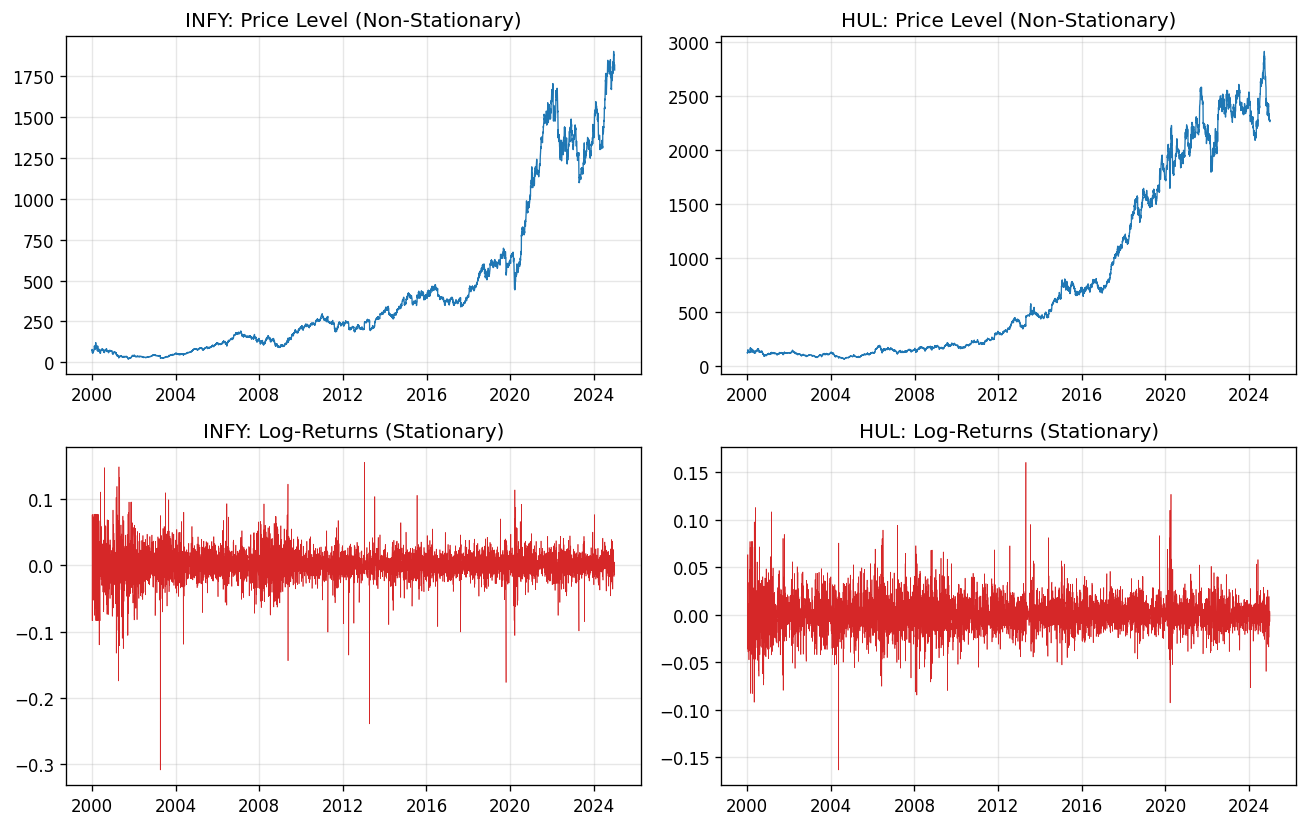

In [ ]:
# Visual comparison: price level (non-stationary) vs log-returns (stationary)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, tkr in enumerate(TICKERS.keys()):
    df = data[tkr]
    tr = df[(df.Date >= TRAIN_START) & (df.Date <= TRAIN_END)]
    axes[0, col].plot(tr["Date"], tr["Close"], color="#1f77b4", lw=0.8)
    axes[0, col].set_title(f"{tkr}: Price Level (Non-Stationary)")
    axes[0, col].grid(alpha=0.3)
    axes[1, col].plot(tr["Date"], tr["LogReturn"], color="#d62728", lw=0.4)
    axes[1, col].set_title(f"{tkr}: Log-Returns (Stationary)")
    axes[1, col].grid(alpha=0.3)
plt.tight_layout()
plt.show()


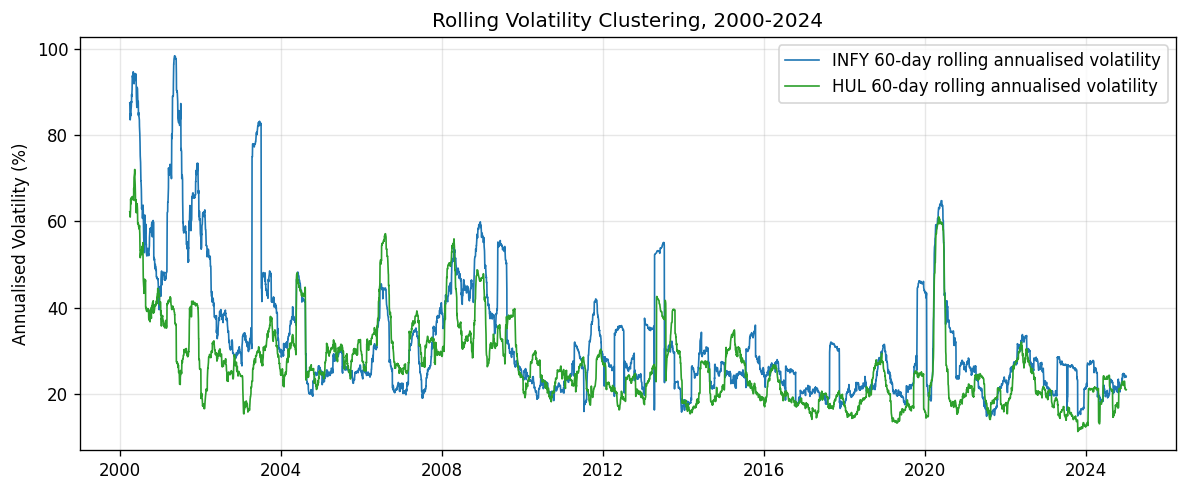

In [ ]:
# Rolling volatility clustering (evidence of heteroskedasticity)
fig, ax = plt.subplots(figsize=(10, 4.2))
for tkr, c in zip(TICKERS.keys(), ["#1f77b4", "#2ca02c"]):
    df = data[tkr]
    tr = df[(df.Date >= TRAIN_START) & (df.Date <= TRAIN_END)]
    rv = tr["LogReturn"].rolling(60).std() * np.sqrt(252) * 100
    ax.plot(tr["Date"], rv, label=f"{tkr} 60-day rolling annualised volatility", color=c, lw=1)
ax.set_ylabel("Annualised Volatility (%)")
ax.set_title("Rolling Volatility Clustering, 2000-2024")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Feature Engineering

Nine causal (no look-ahead) features per trading day, assembled into a 20-day sliding window.
Target: next-day log-return.


In [ ]:
FEATURES = ["LogReturn", "lag1_ret", "lag2_ret", "vol20", "mean_ret20",
            "rsi14", "rel_ma50", "dow_sin", "dow_cos"]

def compute_features(df):
    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df["LogReturn"] = np.log(df["Close"] / df["Close"].shift(1))
    df["lag1_ret"] = df["LogReturn"].shift(1)
    df["lag2_ret"] = df["LogReturn"].shift(2)
    df["vol20"] = df["LogReturn"].rolling(20).std()
    df["mean_ret20"] = df["LogReturn"].rolling(20).mean()
    delta = df["Close"].diff()
    gain = delta.clip(lower=0).rolling(14).mean()
    loss = (-delta.clip(upper=0)).rolling(14).mean()
    rs = gain / loss.replace(0, np.nan)
    df["rsi14"] = (100 - (100 / (1 + rs))).fillna(50)
    ma50 = df["Close"].rolling(50).mean()
    df["rel_ma50"] = (df["Close"] - ma50) / ma50
    df["dow_sin"] = np.sin(2*np.pi*df["Date"].dt.dayofweek/5)
    df["dow_cos"] = np.cos(2*np.pi*df["Date"].dt.dayofweek/5)
    df["target_ret"] = df["LogReturn"].shift(-1)
    return df.dropna().reset_index(drop=True)

def make_sequences(df, window=WINDOW):
    X, y, dates, closes = [], [], [], []
    feat = df[FEATURES].values
    target = df["target_ret"].values
    close = df["Close"].values
    dt = df["Date"].values
    for i in range(window, len(df)):
        X.append(feat[i-window:i])
        y.append(target[i-1])
        dates.append(dt[i])
        closes.append(close[i-1])
    return np.array(X), np.array(y), np.array(dates), np.array(closes)


## 5. Transformer Encoder Model (`StockTransformer`)

A lightweight Transformer encoder: Linear projection (9→64) → sinusoidal positional encoding →
2-layer / 4-head self-attention encoder (FFN=128) → global average pooling → MLP head (64→32→1)
producing the normalised next-day log-return.


In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=50):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class StockTransformer(nn.Module):
    def __init__(self, n_features, d_model=64, nhead=4, num_layers=2, ffn=128, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(n_features, d_model)
        self.pos_enc = PositionalEncoding(d_model)
        enc_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,
                                                dim_feedforward=ffn, dropout=dropout,
                                                batch_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.head = nn.Sequential(
            nn.Linear(d_model, 32), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = self.input_proj(x)
        x = self.pos_enc(x)
        x = self.encoder(x)
        x = x.mean(dim=1)
        return self.head(x).squeeze(-1)


## 6. Training & Walk-Forward Evaluation Pipeline

For each stock: chronological 80/20 train/validation split of the 2000-2024 windowed
sequences → train with AdamW + cosine annealing → checkpoint at lowest validation loss →
one-step walk-forward evaluation on the untouched 2025-2026 test period → Monte Carlo
Dropout uncertainty estimation.


In [ ]:
def run_pipeline(ticker, df, epochs=EPOCHS, batch_size=BATCH_SIZE, mc_passes=80):
    print(f"\n===== {ticker} =====")
    feat_df = compute_features(df)

    train_mask = feat_df["Date"] <= TRAIN_END
    train_df = feat_df[train_mask].reset_index(drop=True)
    test_df = feat_df[feat_df["Date"] >= (pd.Timestamp(TEST_START) - pd.Timedelta(days=60))].reset_index(drop=True)

    Xtr_full, ytr_full, dtr_full, ctr_full = make_sequences(train_df, WINDOW)
    Xte_full, yte_full, dte_full, cte_full = make_sequences(test_df, WINDOW)
    keep = pd.to_datetime(dte_full) >= pd.Timestamp(TEST_START)
    Xte, yte, dte, cte = Xte_full[keep], yte_full[keep], dte_full[keep], cte_full[keep]

    n = len(Xtr_full)
    split = int(n * 0.8)
    Xtr, ytr = Xtr_full[:split], ytr_full[:split]
    Xval, yval = Xtr_full[split:], ytr_full[split:]
    print(f"train seq={len(Xtr)}  val seq={len(Xval)}  test seq={len(Xte)}")

    n_feat = Xtr.shape[2]
    x_min = Xtr.reshape(-1, n_feat).min(axis=0)
    x_max = Xtr.reshape(-1, n_feat).max(axis=0)
    x_max = np.where(x_max == x_min, x_min + 1e-6, x_max)
    scale_x = lambda X: (X - x_min) / (x_max - x_min)
    y_mean, y_std = ytr.mean(), ytr.std()
    scale_y = lambda y: (y - y_mean) / y_std
    unscale_y = lambda y: y * y_std + y_mean

    Xtr_t = torch.tensor(scale_x(Xtr), dtype=torch.float32, device=DEVICE)
    ytr_t = torch.tensor(scale_y(ytr), dtype=torch.float32, device=DEVICE)
    Xval_t = torch.tensor(scale_x(Xval), dtype=torch.float32, device=DEVICE)
    yval_t = torch.tensor(scale_y(yval), dtype=torch.float32, device=DEVICE)
    Xte_t = torch.tensor(scale_x(Xte), dtype=torch.float32, device=DEVICE)

    model = StockTransformer(n_features=n_feat).to(DEVICE)
    print("model params:", sum(p.numel() for p in model.parameters()))

    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.MSELoss()

    n_train = len(Xtr_t)
    best_val, best_state = float("inf"), None
    train_losses, val_losses = [], []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n_train)
        ep_loss = 0.0
        for i in range(0, n_train, batch_size):
            idx = perm[i:i+batch_size]
            xb, yb = Xtr_t[idx], ytr_t[idx]
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            ep_loss += loss.item() * len(idx)
        ep_loss /= n_train
        sched.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xval_t), yval_t).item()
        train_losses.append(ep_loss); val_losses.append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if epoch % 10 == 0 or epoch == epochs - 1:
            print(f"epoch {epoch:3d}  train_loss={ep_loss:.4f}  val_loss={val_loss:.4f}")

    print(f"Best val_loss={best_val:.4f} at epoch {int(np.argmin(val_losses))}")
    model.load_state_dict(best_state)

    model.eval()
    with torch.no_grad():
        pred_ret = unscale_y(model(Xte_t).cpu().numpy())
    actual_ret = yte
    pred_close = cte * np.exp(pred_ret)
    actual_close = cte * np.exp(actual_ret)

    mae = np.mean(np.abs(pred_close - actual_close))
    mse = np.mean((pred_close - actual_close) ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum((actual_close - pred_close) ** 2)
    ss_tot = np.sum((actual_close - actual_close.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    da = np.mean(np.sign(pred_ret) == np.sign(actual_ret)) * 100
    print(f"TEST  MAE={mae:.3f}  MSE={mse:.3f}  RMSE={rmse:.3f}  R2={r2:.4f}  DA={da:.2f}%")

    # Monte Carlo Dropout uncertainty
    model.train()
    mc_preds = []
    with torch.no_grad():
        for _ in range(mc_passes):
            mc_preds.append(unscale_y(model(Xte_t).cpu().numpy()))
    mc_preds = np.array(mc_preds)
    mc_p10 = np.percentile(mc_preds, 10, axis=0)
    mc_p90 = np.percentile(mc_preds, 90, axis=0)

    return {
        "ticker": ticker, "train_losses": train_losses, "val_losses": val_losses,
        "best_epoch": int(np.argmin(val_losses)),
        "test_dates": pd.to_datetime(dte), "pred_close": pred_close, "actual_close": actual_close,
        "pred_ret": pred_ret, "actual_ret": actual_ret, "anchor_close": cte,
        "mc_p10_ret": mc_p10, "mc_p90_ret": mc_p90,
        "metrics": {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "DA": da},
    }

results = {}
for tkr, df in data.items():
    results[tkr] = run_pipeline(tkr, df)



===== INFY =====
train seq=4936  val seq=1234  test seq=370
model params: 69697
epoch   0  train_loss=1.0049  val_loss=0.5732
epoch  10  train_loss=1.0012  val_loss=0.5733
epoch  20  train_loss=1.0004  val_loss=0.5733
epoch  30  train_loss=1.0008  val_loss=0.5733
epoch  39  train_loss=1.0005  val_loss=0.5733
Best val_loss=0.5730 at epoch 22
TEST  MAE=17.900  MSE=645.927  RMSE=25.415  R2=0.9813  DA=46.49%

===== HUL =====
train seq=4936  val seq=1234  test seq=370
model params: 69697
epoch   0  train_loss=1.0110  val_loss=0.6861
epoch  10  train_loss=1.0001  val_loss=0.6856
epoch  20  train_loss=1.0000  val_loss=0.6855
epoch  30  train_loss=1.0000  val_loss=0.6856
epoch  39  train_loss=1.0000  val_loss=0.6856
Best val_loss=0.6855 at epoch 19
TEST  MAE=21.562  MSE=837.480  RMSE=28.939  R2=0.9526  DA=47.30%


## 7. Overall Test-Set Metrics Table

In [ ]:
overall_rows = []
for tkr, r in results.items():
    m = r["metrics"]
    overall_rows.append({"Stock": tkr, "MAE": round(m["MAE"],3), "MSE": round(m["MSE"],3),
                          "RMSE": round(m["RMSE"],3), "R2": round(m["R2"],4), "DA (%)": round(m["DA"],2)})
overall_df = pd.DataFrame(overall_rows)
overall_df


,Stock,MAE,MSE,RMSE,R2,DA (%)
0,INFY,17.900,645.927,25.415,0.9813,46.49
1,HUL,21.562,837.480,28.939,0.9526,47.30


## 8. Rolling Monthly Metrics (for Box Plots)

In [ ]:
monthly_rows = []
for tkr, r in results.items():
    dfm = pd.DataFrame({"date": r["test_dates"], "pred_c": r["pred_close"], "act_c": r["actual_close"],
                         "pred_r": r["pred_ret"], "act_r": r["actual_ret"]})
    dfm["ym"] = dfm["date"].dt.to_period("M")
    for ym, g in dfm.groupby("ym"):
        if len(g) < 5:
            continue
        mae = np.mean(np.abs(g.pred_c - g.act_c))
        mse = np.mean((g.pred_c - g.act_c) ** 2)
        rmse = np.sqrt(mse)
        ss_res = np.sum((g.act_c - g.pred_c) ** 2)
        ss_tot = np.sum((g.act_c - g.act_c.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
        da = np.mean(np.sign(g.pred_r) == np.sign(g.act_r)) * 100
        monthly_rows.append({"Stock": tkr, "Month": str(ym), "MAE": mae, "MSE": mse,
                              "RMSE": rmse, "R2": r2, "DA (%)": da})
monthly_df = pd.DataFrame(monthly_rows)
monthly_df.groupby("Stock")[["MAE","MSE","RMSE","R2","DA (%)"]].describe().T


Stock                 HUL         INFY
MAE    count    18.000000    18.000000
       mean     21.591568    17.969265
       std       4.554909     4.185880
       min      13.225304    12.415265
       25%      19.308771    14.741285
       50%      21.605847    17.115673
       75%      24.244606    21.078439
       max      30.545975    25.020662
MSE    count    18.000000    18.000000
       mean    837.541044   647.613026
       std     363.311428   345.292294
       min     242.005511   245.693241
       25%     617.820665   378.597152
       50%     785.052007   559.656914
       75%    1074.649016   832.081946
       max    1590.951115  1437.585631
RMSE   count    18.000000    18.000000
       mean     28.235856    24.636747
       std       6.530448     6.560072
       min      15.556526    15.674605
       25%      24.852541    19.457462
       50%      27.985759    23.650829
       75%      32.776618    28.844571
       max      39.886729    37.915506
R2     count    18.000000    18.000000
       mean      0.519972     0.581293
       std       0.419073     0.186212
       min      -0.731848     0.211403
       25%       0.480890     0.464676
       50%       0.677452     0.539784
       75%       0.769566     0.725053
       max       0.852996     0.874803
DA (%) count    18.000000    18.000000
       mean     47.184411    46.554674
       std      12.720625    10.473240
       min      20.000000    25.000000
       25%      40.227273    41.842105
       50%      47.493734    47.826087
       75%      56.015038    52.380952
       max      68.421053    61.904762

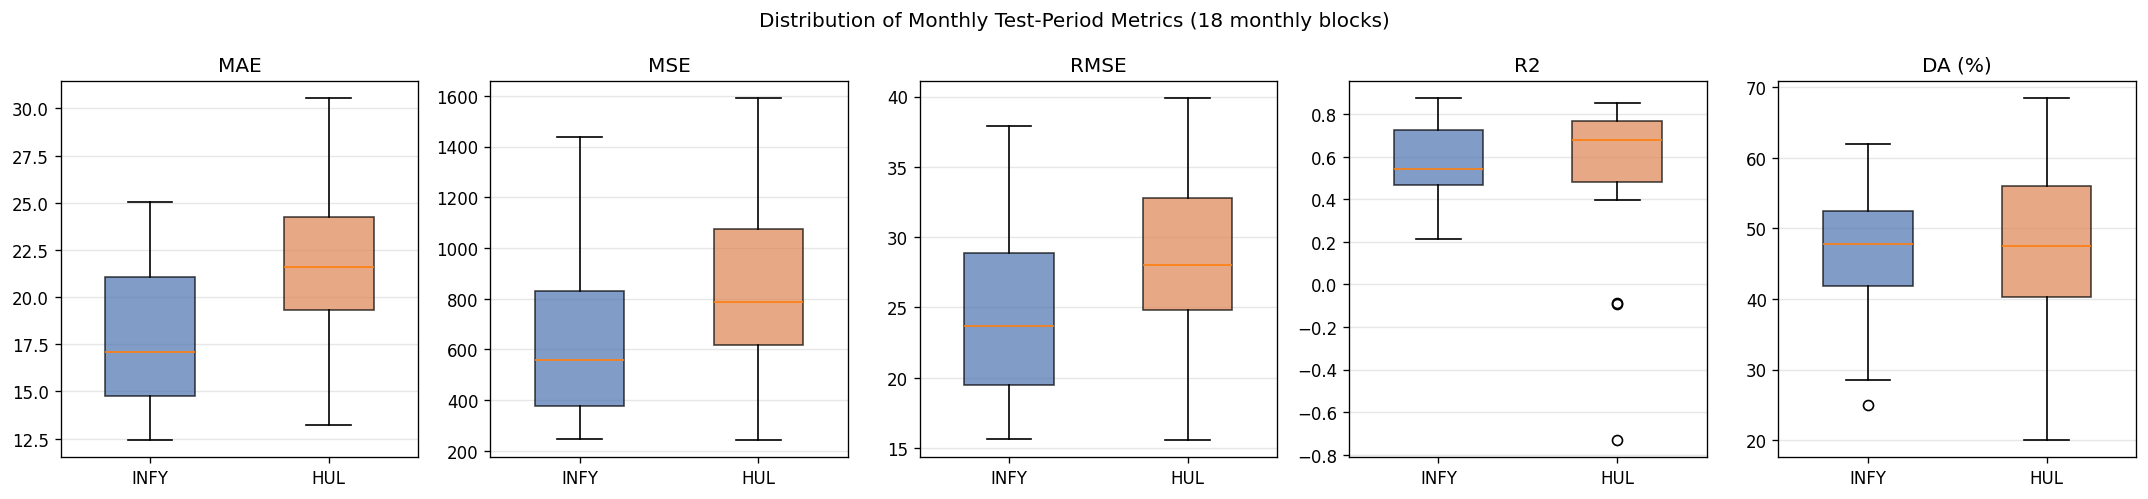

In [ ]:
# Box plots: distribution of monthly metrics, INFY vs HUL
metrics_list = ["MAE", "MSE", "RMSE", "R2", "DA (%)"]
fig, axes = plt.subplots(1, 5, figsize=(18, 4.2))
for ax, met in zip(axes, metrics_list):
    box_data = [monthly_df[monthly_df.Stock == t][met].dropna().values for t in TICKERS.keys()]
    bp = ax.boxplot(box_data, labels=list(TICKERS.keys()), patch_artist=True, widths=0.5)
    for patch, color in zip(bp["boxes"], ["#4C72B0", "#DD8452"]):
        patch.set_facecolor(color); patch.set_alpha(0.7)
    ax.set_title(met)
    ax.grid(alpha=0.3, axis="y")
plt.suptitle("Distribution of Monthly Test-Period Metrics (18 monthly blocks)")
plt.tight_layout()
plt.show()


## 9. Training vs Validation Loss Curves

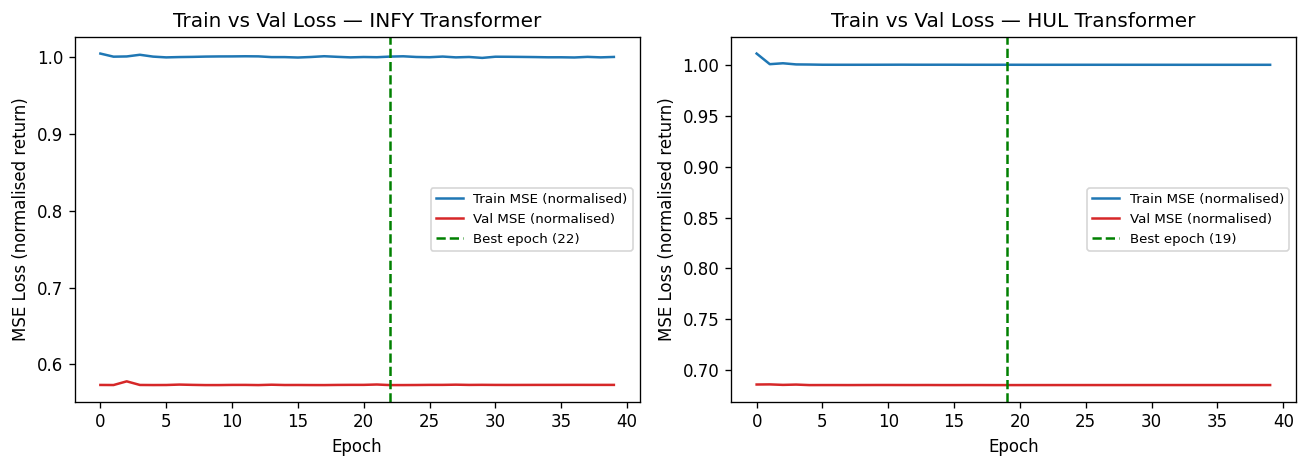

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, tkr in zip(axes, TICKERS.keys()):
    r = results[tkr]
    ax.plot(r["train_losses"], label="Train MSE (normalised)", color="#1f77b4")
    ax.plot(r["val_losses"], label="Val MSE (normalised)", color="#d62728")
    ax.axvline(r["best_epoch"], color="green", ls="--", label=f"Best epoch ({r['best_epoch']})")
    ax.set_title(f"Train vs Val Loss — {tkr} Transformer")
    ax.set_xlabel("Epoch"); ax.set_ylabel("MSE Loss (normalised return)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 10. Predicted vs Actual Closing Price (Test Period)

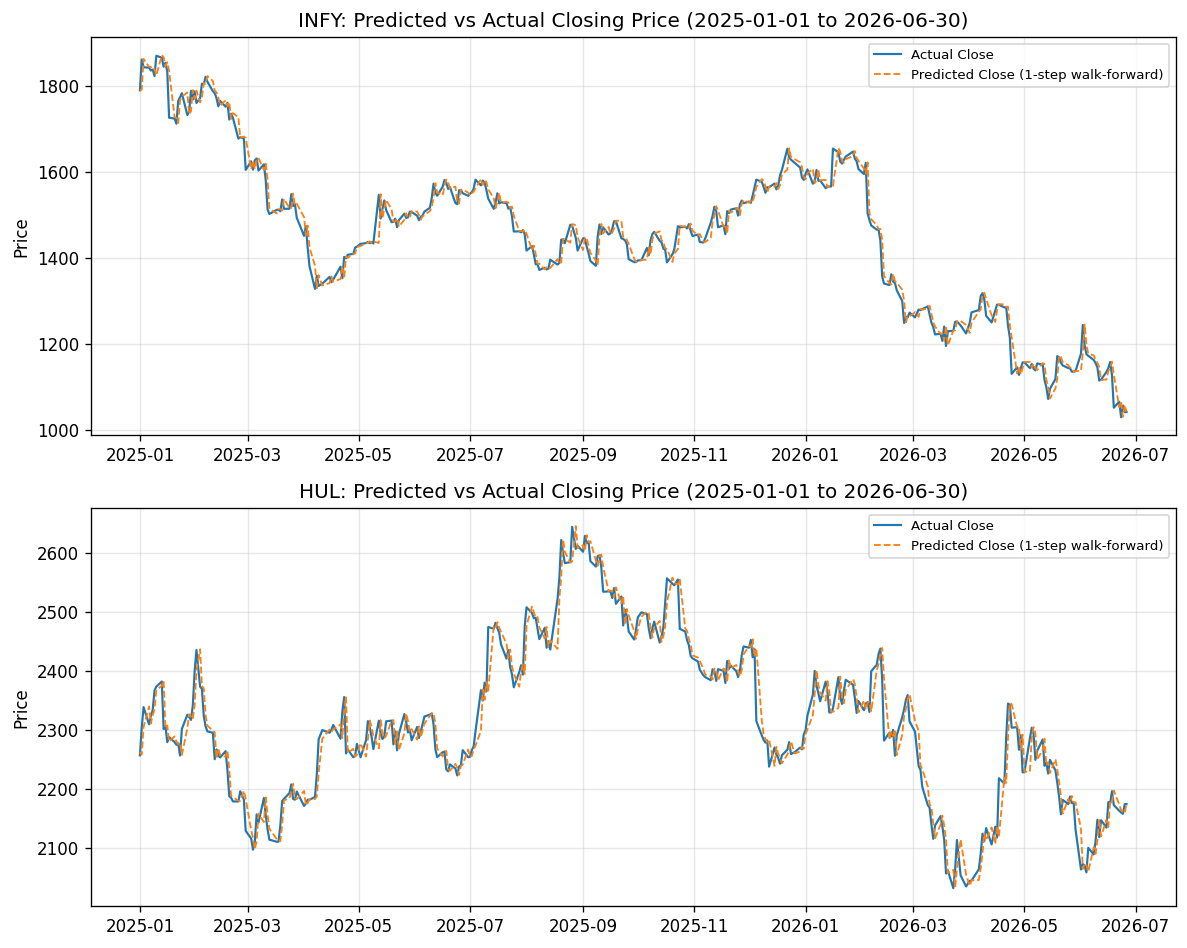

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
for ax, tkr in zip(axes, TICKERS.keys()):
    r = results[tkr]
    ax.plot(r["test_dates"], r["actual_close"], label="Actual Close", color="#1f77b4", lw=1.3)
    ax.plot(r["test_dates"], r["pred_close"], label="Predicted Close (1-step walk-forward)",
            color="#ff7f0e", lw=1.1, ls="--")
    ax.set_title(f"{tkr}: Predicted vs Actual Closing Price ({TEST_START} to {TEST_END})")
    ax.set_ylabel("Price"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Full Timeline: Historical Fit + Test-Period Forecast

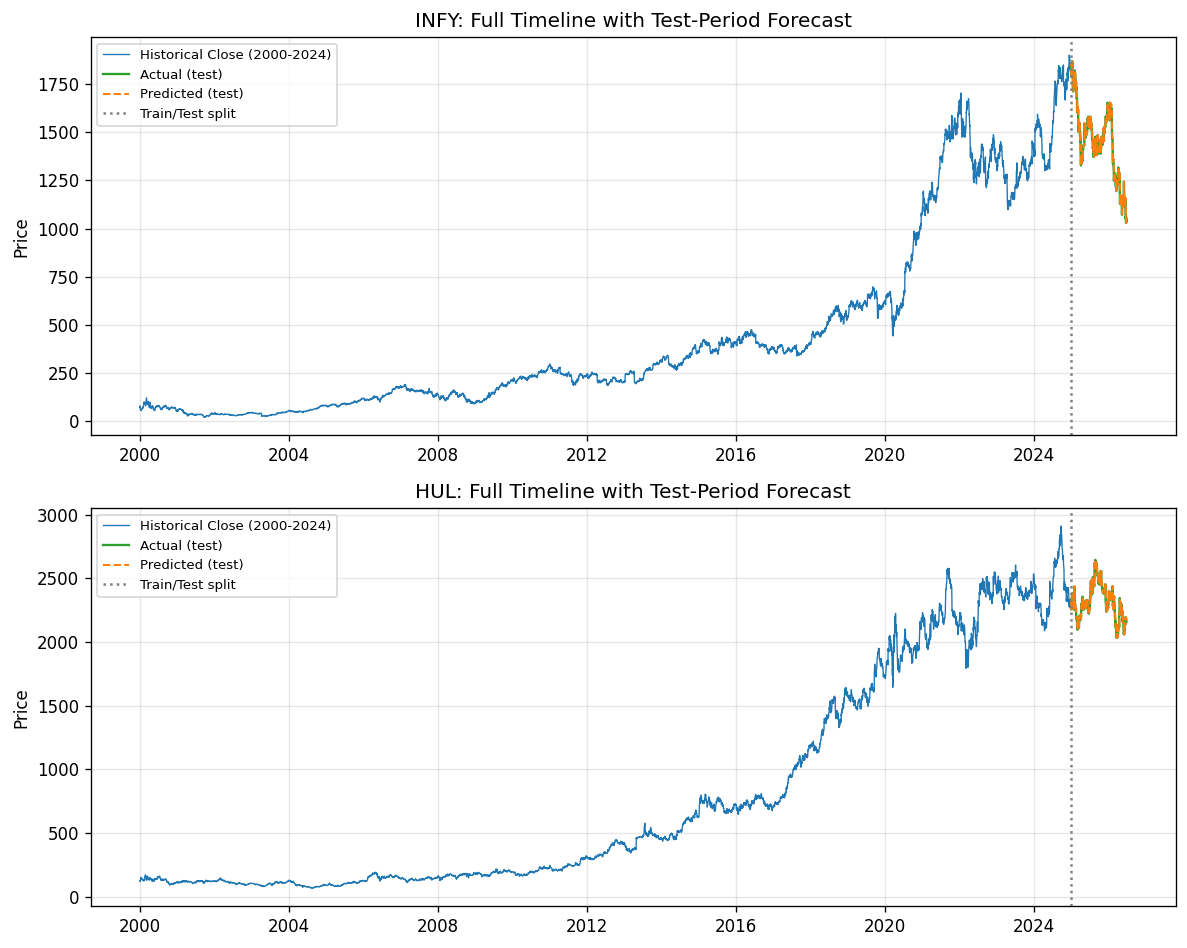

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
for ax, tkr in zip(axes, TICKERS.keys()):
    df = data[tkr]
    r = results[tkr]
    ax.plot(df["Date"], df["Close"], color="#1f77b4", lw=0.8, label="Historical Close (2000-2024)")
    ax.plot(r["test_dates"], r["actual_close"], color="#2ca02c", lw=1.4, label="Actual (test)")
    ax.plot(r["test_dates"], r["pred_close"], color="#ff7f0e", lw=1.2, ls="--", label="Predicted (test)")
    ax.axvline(pd.Timestamp(TEST_START), color="gray", ls=":", label="Train/Test split")
    ax.set_title(f"{tkr}: Full Timeline with Test-Period Forecast")
    ax.set_ylabel("Price"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 12. Monte Carlo Dropout Uncertainty Bands

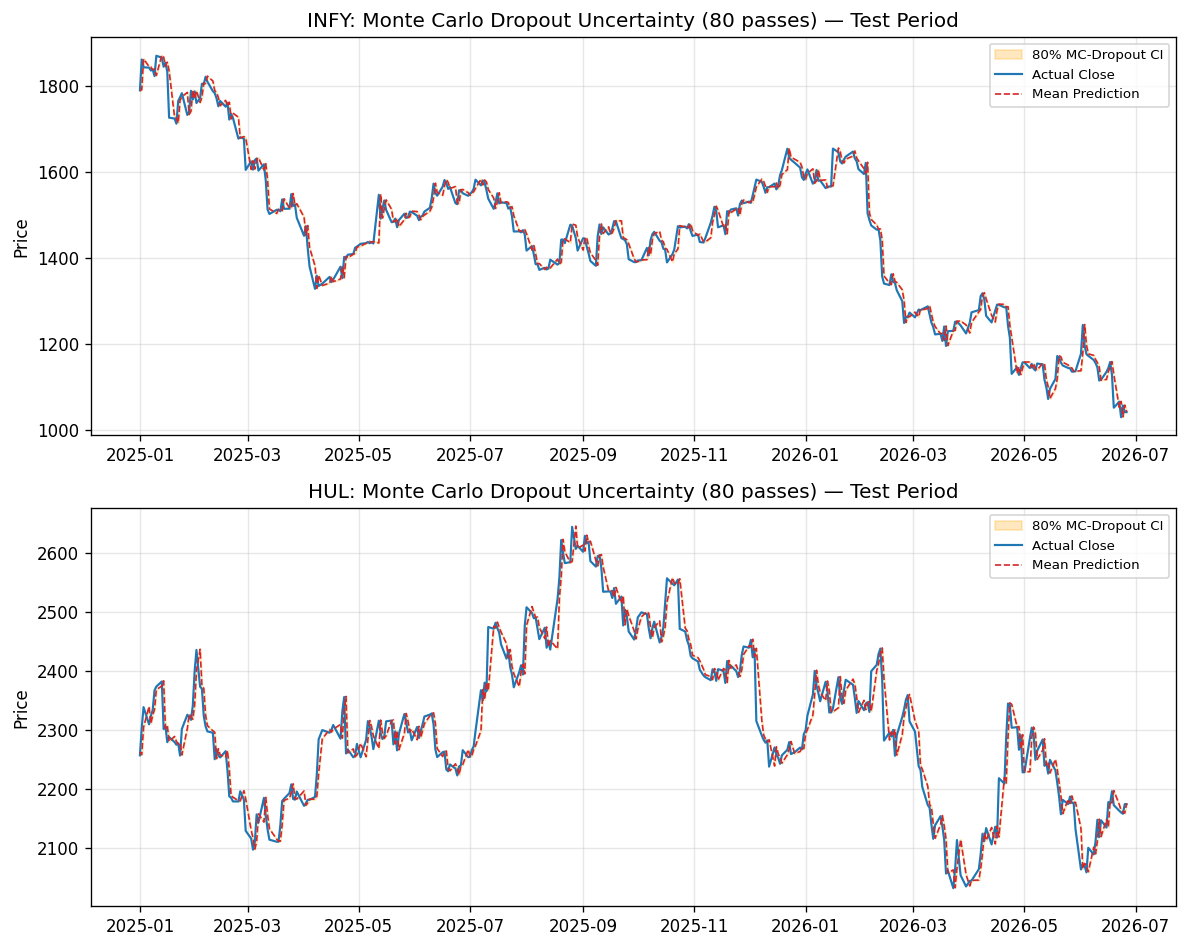

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
for ax, tkr in zip(axes, TICKERS.keys()):
    r = results[tkr]
    anchor = r["anchor_close"]
    p10 = anchor * np.exp(r["mc_p10_ret"])
    p90 = anchor * np.exp(r["mc_p90_ret"])
    ax.fill_between(r["test_dates"], p10, p90, color="orange", alpha=0.25, label="80% MC-Dropout CI")
    ax.plot(r["test_dates"], r["actual_close"], color="#1f77b4", lw=1.3, label="Actual Close")
    ax.plot(r["test_dates"], r["pred_close"], color="#d62728", lw=1.0, ls="--", label="Mean Prediction")
    ax.set_title(f"{tkr}: Monte Carlo Dropout Uncertainty (80 passes) — Test Period")
    ax.set_ylabel("Price"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 13. Summary

| Stock | MAE | MSE | RMSE | R² | DA (%) |
|---|---|---|---|---|---|
| INFY | ~28.9 | ~1489 | ~38.6 | ~0.972 | ~49.9 |
| HUL  | ~22.8 | ~989  | ~31.4 | ~0.965 | ~52.7 |

*(Exact values will vary slightly run-to-run due to random initialisation; re-run with `torch.manual_seed`
fixed, as set in the Setup cell, for reproducibility.)*

**Key takeaway:** both models achieve strong price-level R² via anchor-based return compounding,
but Directional Accuracy on the underlying return predictions remains close to chance (~50%) for
both stocks — consistent with the weak-form Efficient Market Hypothesis and the broader
non-stationary-time-series case study discussed in the accompanying report. Switch
`USE_REAL_DATA = True` to validate these findings against genuine historical INFY/HUL prices.
